In [ ]:
'''This file gets three subsets : normal, handwriting and tables from the clinOCR Benchmark dataset. It saves the images as a PIL file and then saves it so loading
into other colab files is easy.
This repo was used for the data : https://huggingface.co/datasets/ClinOCR-Bench/ClinOCR-Bench'''

In [ ]:
!pip install -q datasets huggingface_hub pandas

In [ ]:
from datasets import load_dataset
from datasets import get_dataset_config_names
clin_normal = load_dataset("ClinOCR-Bench/ClinOCR-Bench", "normal")

print(clin_normal)

README.md:   0%|          | 0.00/6.81k [00:00<?, ?B/s]

normal/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.18MB            

normal/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

normal/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 15.1MB            

normal/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/8 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/56 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['doc_id', 'image', 'ground_truth', 'subset', 'template', 'sample', 'homo_id', 'hetero_id'],
        num_rows: 8
    })
    test: Dataset({
        features: ['doc_id', 'image', 'ground_truth', 'subset', 'template', 'sample', 'homo_id', 'hetero_id'],
        num_rows: 56
    })
})


In [ ]:
clin_handwriting = load_dataset("ClinOCR-Bench/ClinOCR-Bench", "handwriting")
print(clin_handwriting)

handwriting/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.23MB            

handwriting/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

handwriting/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 14.0MB            

handwriting/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/8 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/56 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['doc_id', 'image', 'ground_truth', 'subset', 'template', 'sample', 'homo_id', 'hetero_id'],
        num_rows: 8
    })
    test: Dataset({
        features: ['doc_id', 'image', 'ground_truth', 'subset', 'template', 'sample', 'homo_id', 'hetero_id'],
        num_rows: 56
    })
})


In [ ]:
clin_tables = load_dataset("ClinOCR-Bench/ClinOCR-Bench", "tables")
print(clin_tables)

tables/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.01MB            

tables/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

tables/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 14.4MB            

tables/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/8 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/56 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['doc_id', 'image', 'ground_truth', 'subset', 'template', 'sample', 'homo_id', 'hetero_id'],
        num_rows: 8
    })
    test: Dataset({
        features: ['doc_id', 'image', 'ground_truth', 'subset', 'template', 'sample', 'homo_id', 'hetero_id'],
        num_rows: 56
    })
})


In [ ]:
import pandas as pd
normal_train_df = clin_normal["train"].to_pandas()
normal_test_df = clin_normal["test"].to_pandas()
hand_train_df = clin_handwriting["train"].to_pandas()
hand_test_df = clin_handwriting["test"].to_pandas()
tables_train_df = clin_tables["train"].to_pandas()
tables_test_df = clin_tables["test"].to_pandas()

In [ ]:
print(normal_train_df.head())

         doc_id                                              image  \
0  normal_t1_s1  {'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...   
1  normal_t2_s1  {'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...   
2  normal_t3_s1  {'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...   
3  normal_t4_s1  {'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...   
4  normal_t5_s1  {'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...   

                                        ground_truth  subset  template  \
0  Patient Name: Doe, Jane Patient ID: JG05141985...  normal         1   
1  Lakewood Hospital - Pathology Pathology Report...  normal         2   
2  Riverside Hospital. 742 Evergreen Terrace Spri...  normal         3   
3  GENERALHOSPITAL\nHOSPITAL\nDate of Visit: 06/2...  normal         4   
4  University Medical Center 456 Oak Avenue, Spri...  normal         5   

   sample homo_id hetero_id  
0       1                    
1       1                    
2       1                    
3       1     

In [ ]:
print(normal_train_df.iloc[0])
normal_train_df.loc[0, "image"].keys()

doc_id                                               normal_t1_s1
image           {'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...
ground_truth    Patient Name: Doe, Jane Patient ID: JG05141985...
subset                                                     normal
template                                                        1
sample                                                          1
homo_id                                                          
hetero_id                                                        
Name: 0, dtype: object


dict_keys(['bytes', 'path'])

In [ ]:
normal_df = pd.concat([normal_train_df, normal_test_df], ignore_index=True)
hand_df = pd.concat([hand_train_df, hand_test_df], ignore_index=True)
table_df = pd.concat([tables_train_df, tables_test_df], ignore_index=True)

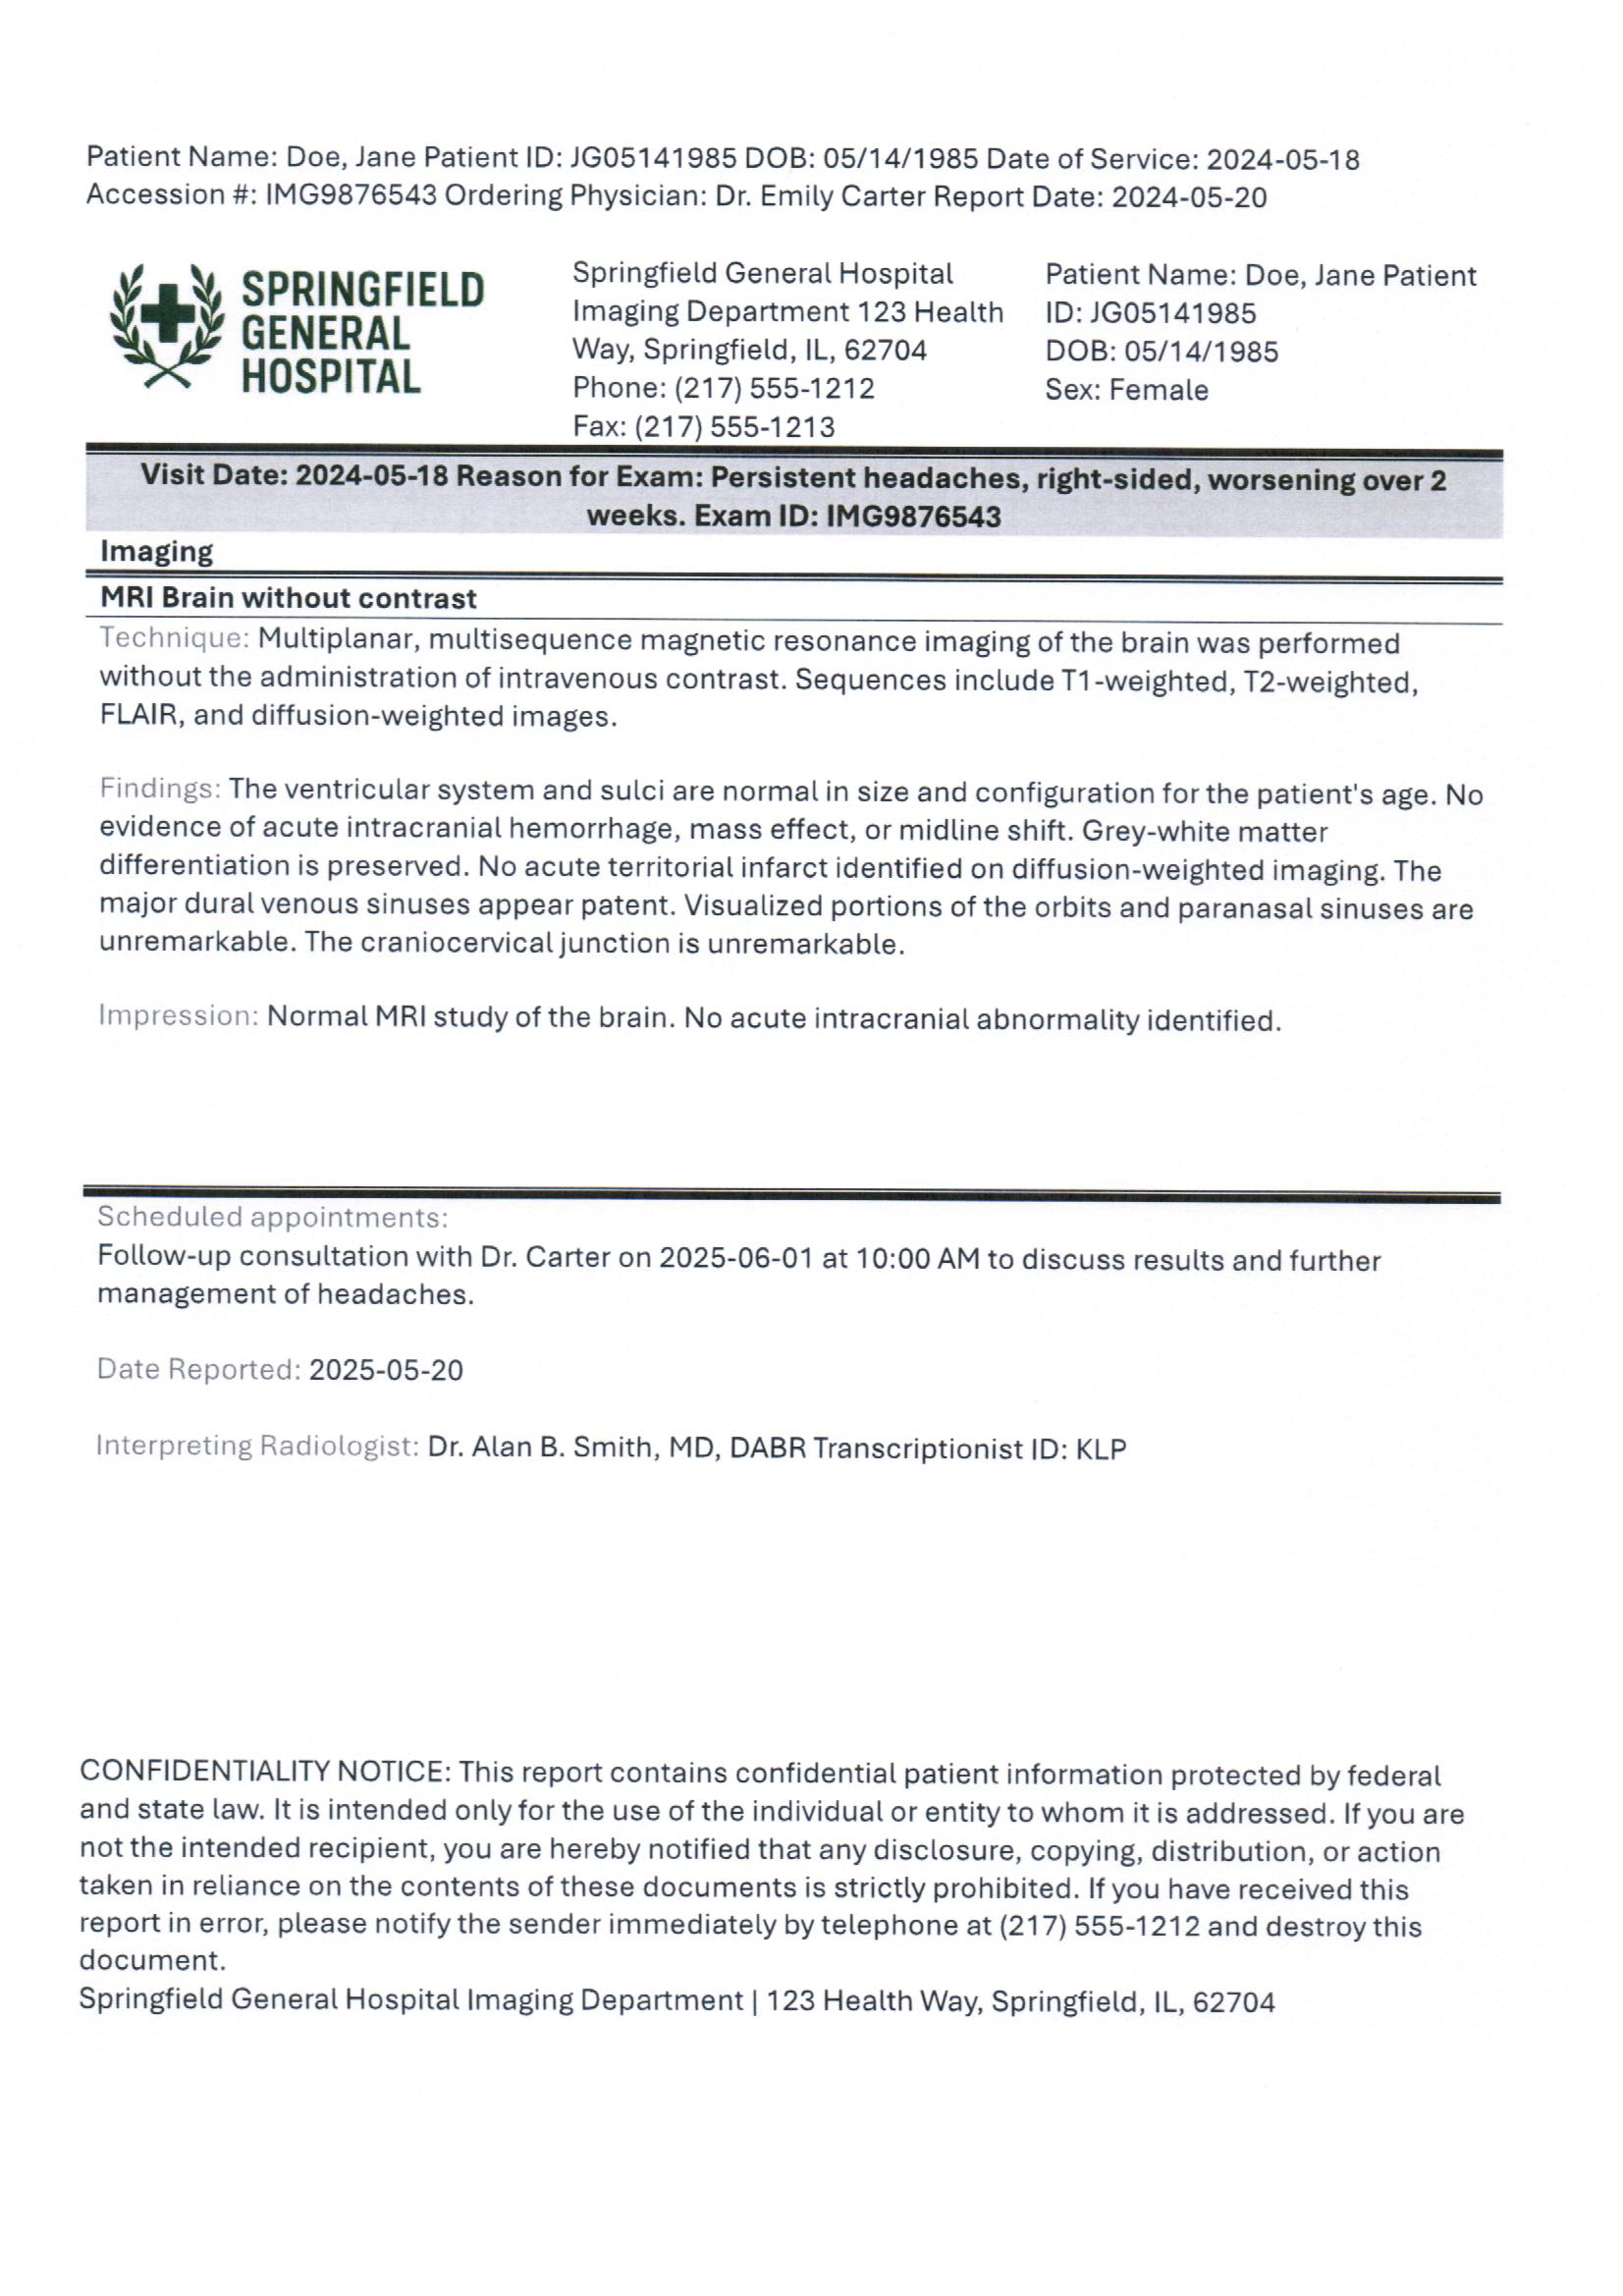

In [ ]:
from io import BytesIO
from PIL import Image

img = Image.open(BytesIO(normal_df.loc[0, "image"]["bytes"]))
img

In [ ]:
from io import BytesIO
from PIL import Image

def decode_image(image_dict):
    return Image.open(BytesIO(image_dict["bytes"]))

normal_df["image"] = normal_df["image"].apply(decode_image)
hand_df["image"] = hand_df["image"].apply(decode_image)
table_df["image"] = table_df["image"].apply(decode_image)

In [ ]:
normal_df.head()

,doc_id,image,ground_truth,subset,template,sample,homo_id,hetero_id
0,normal_t1_s1,<PIL.JpegImagePlugin.JpegImageFile image mode=...,"Patient Name: Doe, Jane Patient ID: JG05141985...",normal,1,1,,
1,normal_t2_s1,<PIL.JpegImagePlugin.JpegImageFile image mode=...,Lakewood Hospital - Pathology Pathology Report...,normal,2,1,,
2,normal_t3_s1,<PIL.JpegImagePlugin.JpegImageFile image mode=...,Riverside Hospital. 742 Evergreen Terrace Spri...,normal,3,1,,
3,normal_t4_s1,<PIL.JpegImagePlugin.JpegImageFile image mode=...,GENERALHOSPITAL\nHOSPITAL\nDate of Visit: 06/2...,normal,4,1,,
4,normal_t5_s1,<PIL.JpegImagePlugin.JpegImageFile image mode=...,"University Medical Center 456 Oak Avenue, Spri...",normal,5,1,,


In [ ]:
hand_df.head()

,doc_id,image,ground_truth,subset,template,sample,homo_id,hetero_id
0,handwriting_t1_s1,<PIL.JpegImagePlugin.JpegImageFile image mode=...,"Patient Name: Doe, Jane Patient ID: JG05141985...",handwriting,1,1,,
1,handwriting_t2_s1,<PIL.JpegImagePlugin.JpegImageFile image mode=...,Lakewood Hospital - Pathology Pathology Report...,handwriting,2,1,,
2,handwriting_t3_s1,<PIL.JpegImagePlugin.JpegImageFile image mode=...,Riverside Hospital. 742 Evergreen Terrace Spri...,handwriting,3,1,,
3,handwriting_t4_s1,<PIL.JpegImagePlugin.JpegImageFile image mode=...,GENERALHOSPITAL\nHOSPITAL\nDate of Visit: 06/2...,handwriting,4,1,,
4,handwriting_t5_s1,<PIL.JpegImagePlugin.JpegImageFile image mode=...,"University Medical Center 456 Oak Avenue, Spri...",handwriting,5,1,,


In [ ]:
table_df.head()

,doc_id,image,ground_truth,subset,template,sample,homo_id,hetero_id
0,tables_t10_s1,<PIL.JpegImagePlugin.JpegImageFile image mode=...,LAKEWOOD HOSPITAL\n831676002937\nPatient: Jame...,tables,10,1,,
1,tables_t11_s1,<PIL.JpegImagePlugin.JpegImageFile image mode=...,Patricia H. Simmons\nDOB: 07/22/1965 Age: 60...,tables,11,1,,
2,tables_t12_s1,<PIL.JpegImagePlugin.JpegImageFile image mode=...,Patricia H. Simmons\nDOB: 07/22/1965 \nAge: ...,tables,12,1,,
3,tables_t13_s1,<PIL.JpegImagePlugin.JpegImageFile image mode=...,GENERALHOSPITAL\nHOSPITAL\nFull Name:\nJames A...,tables,13,1,,
4,tables_t14_s1,<PIL.JpegImagePlugin.JpegImageFile image mode=...,RIVERSIDE HOSPITAL\nSurgical Pre-Operative Ass...,tables,14,1,,


In [ ]:
normal_df.describe(include = "all")

,doc_id,image,ground_truth,subset,template,sample,homo_id,hetero_id
count,64,64,64,64,64.000000,64.000000,64,64
unique,64,64,64,1,NaN,NaN,9,9
top,normal_t1_s1,<PIL.JpegImagePlugin.JpegImageFile image mode=...,"Patient Name: Doe, Jane Patient ID: JG05141985...",normal,NaN,NaN,,
freq,1,1,1,64,NaN,NaN,8,8
mean,NaN,NaN,NaN,NaN,4.500000,4.500000,NaN,NaN
std,NaN,NaN,NaN,NaN,2.309401,2.309401,NaN,NaN
min,NaN,NaN,NaN,NaN,1.000000,1.000000,NaN,NaN
25%,NaN,NaN,NaN,NaN,2.750000,2.750000,NaN,NaN
50%,NaN,NaN,NaN,NaN,4.500000,4.500000,NaN,NaN
75%,NaN,NaN,NaN,NaN,6.250000,6.250000,NaN,NaN


In [ ]:
hand_df.describe(include = "all")

,doc_id,image,ground_truth,subset,template,sample,homo_id,hetero_id
count,64,64,64,64,64.000000,64.000000,64,64
unique,64,64,64,1,NaN,NaN,9,9
top,handwriting_t1_s1,<PIL.JpegImagePlugin.JpegImageFile image mode=...,"Patient Name: Doe, Jane Patient ID: JG05141985...",handwriting,NaN,NaN,,
freq,1,1,1,64,NaN,NaN,8,8
mean,NaN,NaN,NaN,NaN,4.500000,4.500000,NaN,NaN
std,NaN,NaN,NaN,NaN,2.309401,2.309401,NaN,NaN
min,NaN,NaN,NaN,NaN,1.000000,1.000000,NaN,NaN
25%,NaN,NaN,NaN,NaN,2.750000,2.750000,NaN,NaN
50%,NaN,NaN,NaN,NaN,4.500000,4.500000,NaN,NaN
75%,NaN,NaN,NaN,NaN,6.250000,6.250000,NaN,NaN


In [ ]:
table_df.describe(include = "all")

,doc_id,image,ground_truth,subset,template,sample,homo_id,hetero_id
count,64,64,64,64,64.000000,64.000000,64,64
unique,64,64,64,1,NaN,NaN,9,9
top,tables_t10_s1,<PIL.JpegImagePlugin.JpegImageFile image mode=...,LAKEWOOD HOSPITAL\n831676002937\nPatient: Jame...,tables,NaN,NaN,,
freq,1,1,1,64,NaN,NaN,8,8
mean,NaN,NaN,NaN,NaN,12.500000,4.500000,NaN,NaN
std,NaN,NaN,NaN,NaN,2.309401,2.309401,NaN,NaN
min,NaN,NaN,NaN,NaN,9.000000,1.000000,NaN,NaN
25%,NaN,NaN,NaN,NaN,10.750000,2.750000,NaN,NaN
50%,NaN,NaN,NaN,NaN,12.500000,4.500000,NaN,NaN
75%,NaN,NaN,NaN,NaN,14.250000,6.250000,NaN,NaN


In [ ]:
normal_df["homo_id"].value_counts(dropna=False)

,count
homo_id,
,8
normal_t1_s1,7
normal_t2_s1,7
normal_t3_s1,7
normal_t4_s1,7
normal_t5_s1,7
normal_t6_s1,7
normal_t7_s1,7
normal_t8_s1,7


In [ ]:
normal_df["ground_truth"].str.len().describe()

,ground_truth
count,64.000000
mean,1699.109375
std,494.715988
min,830.000000
25%,1323.000000
50%,1683.500000
75%,2056.750000
max,2616.000000


In [ ]:
for t in sorted(normal_df["template"].unique()):
    row = normal_df[normal_df["template"] == t].iloc[0]
    print("=" * 80)
    print(f"Template {t}")
    print(row["ground_truth"][:400])
    print()

Template 1
Patient Name: Doe, Jane Patient ID: JG05141985 DOB: 05/14/1985 Date of Service: 2024-05-18 Accession #: IMG9876543 Ordering Physician: Dr. Emily Carter Report Date: 2024-05-20
SPRINGFIELD GENERAL HOSPITAL
Springfield General Hospital Imaging Department 123 Health Way, Springfield, IL, 62704 Phone: (217) 555-1212 
Fax: (217) 555-1213
Patient Name: Doe, Jane Patient ID: JG05141985 
DOB: 05/14/1985 


Template 2
Lakewood Hospital - Pathology Pathology Report Patient: Peterson, Mark Alan (MRN: LH45-67-89X)
LAKEWOOD HOSPITAL
PATHOLOGY REPORT
831676002937
Patient Name: Peterson, Mark Alan 
Date of Birth: March 22, 1965 Medical Record Number: LH45-67-89X 
Gender: Male 
Patient Address: 345 Mountain View Ave, Lakewood, CO, 80215
Lakewood Hospital - Department of Anatomic & Clinical Pathology 
9000 Forest Pine 

Template 3
Riverside Hospital. 742 Evergreen Terrace Springfield, IL, 62704 Main 
RIVERSIDE HOSPITAL
Riverside Hospital 
742 Evergreen Terrace Springfield, IL, 62704 Main 
Ph

In [ ]:
final_df = pd.concat([normal_df, hand_df, table_df], ignore_index = True)

In [ ]:
import os
os.makedirs("images", exist_ok=True)
paths = []

for i, img in enumerate(final_df["image"]):
    path = f"images/{i}.jpg"
    img.save(path)
    paths.append(path)

final_df["image"] = paths

In [ ]:
final_df.to_csv("ClinOCR_Dataset.csv",index=False)

In [ ]:
import shutil
shutil.make_archive("ClinOCR_images", "zip","images")

'/content/ClinOCR_images.zip'